In [5]:
# Import packages
import torch
import numpy as np
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from simpletransformers.classification import ClassificationModel
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [6]:
# Read the files
df_top_1000 = pd.read_csv("./data/top_1000_tags.csv")
df_char_nar_annotations = pl.read_csv("./data/df_unique.csv")

train_data = df_top_1000[["Tag", "Character"]].copy()

# Encode the Character column as numbers
le_char = preprocessing.LabelEncoder()
train_data["labels"] = le_char.fit_transform(train_data["Character"])

train_data = train_data.rename(columns={"Tag": "text",}) # Rename the columns

train_data = train_data[["text", "labels"]]

In [11]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Prepare 5-fold cross validation

results = {
    "accuracy": [],
    "precision_macro": [],
    "precision_weighted": [],
    "recall_macro": [],
    "recall_weighted": [],
    "f1_macro": [],
    "f1_weighted": []
}

all_true = []
all_pred = []

for fold, (train_index, val_index) in enumerate(kf.split(train_data["text"], train_data["labels"]), start=1):
    print(f"\nFold {fold}")
    # Splitting Dataframe
    train_df = train_data.iloc[train_index].copy()
    val_df = train_data.iloc[val_index].copy()

    # Defining the model
    model = ClassificationModel(
        'bert',
        'bert-base-uncased',
        num_labels=6,
        use_cuda=True,
        args={
            "num_train_epochs": 3,
            "train_batch_size": 16,
            "eval_batch_size": 16,
            "overwrite_output_dir": True,
            "reprocess_input_data": True,
            "save_eval_checkpoints": False,
            "save_model_every_epoch": False
        }
    )


    model.train_model(train_df) # Train the model

    # Validate the model
    result, model_outputs, wrong_predictions = model.eval_model(val_df, acc=accuracy_score)

    predictions = np.argmax(model_outputs, axis=1) # Get predictions
    true_labels = val_df["labels"].to_numpy() # Get true labels

    all_true.extend(true_labels)
    all_pred.extend(predictions)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predictions)

    precision_macro = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    precision_weighted = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall_macro = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    recall_weighted = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1_macro = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    f1_weighted = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store results
    results["accuracy"].append(accuracy)
    results["precision_macro"].append(precision_macro)
    results["precision_weighted"].append(precision_weighted)
    results["recall_macro"].append(recall_macro)
    results["recall_weighted"].append(recall_weighted)
    results["f1_macro"].append(f1_macro)
    results["f1_weighted"].append(f1_weighted)

    # Print confusion matrix
    cm = confusion_matrix(true_labels, predictions)
    print(cm)
    # Print scores for this fold
    print("Accuracy:", accuracy)
    print("Precision Macro:", precision_macro)
    print("Precision Weighted:", precision_weighted)
    print("Recall Macro:", recall_macro)
    print("Recall Weighted:", recall_weighted)
    print("F1 Macro:", f1_macro)
    print("F1 Weighted:", f1_weighted)
    print("\nClassification Report:")
    print(classification_report(
            true_labels,
            predictions,
            target_names=le_char.classes_,
            zero_division=0
        )
    )


Fold 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:   0%|          | 0/3 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


... (61 outputs left out)

0it [00:00, ?it/s]

Running Evaluation:   0%|          | 0/13 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:1570: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


[[13  0  6  0  0  2]
 [ 0 26  3  0  0  1]
 [ 6  1 82  0  0  6]
 [ 0  3  0  0  0  1]
 [ 0  3  7  0  0  1]
 [ 0  2  6  0  0 31]]
Accuracy: 0.76
Precision Macro: 0.49227074095495144
Precision Weighted: 0.7017184788895315
Recall Macro: 0.5239573292204871
Recall Weighted: 0.76
F1 Macro: 0.5065921169634179
F1 Weighted: 0.72896654569142

Classification Report:
                      precision    recall  f1-score   support

           Biography       0.68      0.62      0.65        21
Emotion/Mental State       0.74      0.87      0.80        30
        No Character       0.79      0.86      0.82        95
         Personality       0.00      0.00      0.00         4
    Physical Feature       0.00      0.00      0.00        11
        Relationship       0.74      0.79      0.77        39

            accuracy                           0.76       200
           macro avg       0.49      0.52      0.51       200
        weighted avg       0.70      0.76      0.73       200



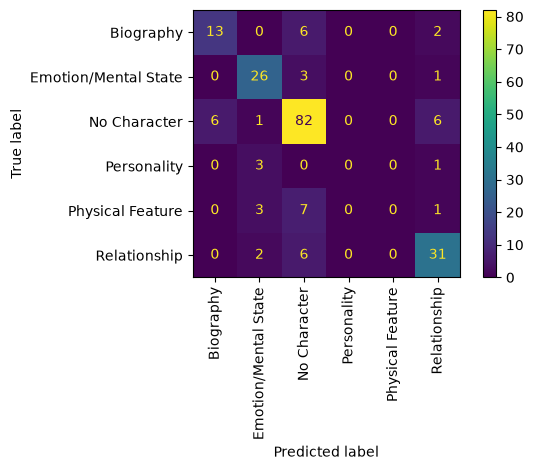


Overall 5-Fold Classification Report:
                      precision    recall  f1-score   support

           Biography       0.66      0.61      0.63       106
Emotion/Mental State       0.74      0.78      0.76       152
        No Character       0.78      0.89      0.83       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       0.83      0.09      0.16        55
        Relationship       0.76      0.75      0.75       195

            accuracy                           0.76      1000
           macro avg       0.63      0.52      0.52      1000
        weighted avg       0.75      0.76      0.73      1000



{'Accuracy Mean': np.float64(0.756),
 'Accuracy SD': np.float64(0.020432816741702567),
 'Precision Macro Mean': np.float64(0.585512679950865),
 'Precision Macro SD': np.float64(0.08593088388479149),
 'Precision Weighted Mean': np.float64(0.7337068113167633),
 'Precision Weighted SD': np.float64(0.03458808240166976),
 'Recall Macro Mean': np.float64(0.5201074477305376),
 'Recall Macro SD': np.float64(0.026293087962652582),
 'Recall Weighted Mean': np.float64(0.756),
 'Recall Weighted SD': np.float64(0.020432816741702567),
 'F1 Macro Mean': np.float64(0.5204241497403486),
 'F1 Macro SD': np.float64(0.030798788819085484),
 'F1 Weighted Mean': np.float64(0.730783923298467),
 'F1 Weighted SD': np.float64(0.021953231004180177)}

In [16]:
cm = confusion_matrix(true_labels, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_char.classes_
)

disp.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report across all 5 folds
print("\nOverall 5-Fold Classification Report:")
print(
    classification_report(
        all_true,
        all_pred,
        target_names=le_char.classes_,
        zero_division=0
    )
)

bert_results = {
    "Accuracy Mean": np.mean(results["accuracy"]),
    "Accuracy SD": np.std(results["accuracy"], ddof=1),
    "Precision Macro Mean": np.mean(results["precision_macro"]),
    "Precision Macro SD": np.std(results["precision_macro"], ddof=1),
    "Precision Weighted Mean": np.mean(results["precision_weighted"]),
    "Precision Weighted SD": np.std(results["precision_weighted"], ddof=1),
    "Recall Macro Mean": np.mean(results["recall_macro"]),
    "Recall Macro SD": np.std(results["recall_macro"], ddof=1),
    "Recall Weighted Mean": np.mean(results["recall_weighted"]),
    "Recall Weighted SD": np.std(results["recall_weighted"], ddof=1),
    "F1 Macro Mean": np.mean(results["f1_macro"]),
    "F1 Macro SD": np.std(results["f1_macro"], ddof=1),
    "F1 Weighted Mean": np.mean(results["f1_weighted"]),
    "F1 Weighted SD": np.std(results["f1_weighted"], ddof=1)
}

bert_results